# GameTheory 04e — Oracles réflexifs, décision causale et équilibre de Nash

**Navigation** : [<< 4d-Marchandage-Asymetrique](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb) | [Index](README.md) | [DecInfer 09-Théories-Decision-Predicteur (inter-séries) >>](../Probas/DecisionTheory/DecInfer/DecInfer-09-Theories-Decision-Predicteur-Python.ipynb) | [jumeau Python](GameTheory-04e-Reflective-Oracles-Python.ipynb)

> **Source primaire** : Benja Fallenstein, Jessica Taylor, Paul F. Christiano (2015), *Reflective Oracles: A Foundation for Classical Game Theory*. arXiv : [1508.04145](https://arxiv.org/abs/1508.04145). Bibliothèque canonique privée : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\Cooperative Games and the Shapley Value\2015 - Fallenstein Taylor Christiano - Reflective Oracles - A Foundation for Classical Game Theory.pdf` (SHA-256 `c0ae7668...ee6653`).

Ce notebook étend la grappe `GameTheory-04*` en introduisant l'**auto-référence computationnelle** : un agent qui peut se demander *ce qu'un autre agent, capable de le modéliser, ferait*. Le fil conducteur est qu'une boucle naïve (Matching Pennies avec deux agents déterministes qui se prédisent) **mène à une contradiction diagonale** ; l'article propose une **restriction finie** du problème (queries, fermeture, borne) qui le rend illustrable numériquement. L'objectif pédagogique est de rendre l'articulation entre :

- théorie causale de la décision (CDT) et équilibre de Nash (théorème 4.1),
- la construction d'un oracle réflexif *fini* (théorème 5.1),
- les limites : le résultat fini illustratif **n'est pas** l'oracle universel du théorème 2.1 (point fixe de Kakutani en dimension infinie).

Ce notebook étend la grappe `GameTheory-04*` en introduisant l'**auto-référence computationnelle** : un agent qui peut se demander *ce qu'un autre agent, capable de le modéliser, ferait*. Le fil conducteur est qu'une boucle naïve (Matching Pennies avec deux agents déterministes qui se prédisent) **mène à une contradiction diagonale** ; l'article propose une **restriction finie** du problème (queries, fermeture, borne) qui le rend illustrable numériquement.

**Position dans le parcours Expert / informatique théorique** : prolonge `GameTheory-04-NashEquilibrium-Python` (stratégies mixtes, Matching Pennies) et `GameTheory-04c-NashExistence-Python` (point fixe Brouwer discriminant — cellule `perturbed_br`, anti-tautologie Prong-B). Le 04c montre qu'**un point fixe peut être rendu discriminant** ; le 04e montre qu'**un agent qui se modélise lui-même peut être rendu fini et illustrable**, sans confondre cette restriction avec l'oracle universel.

## 0. Imports et constantes

L'environnement n'a aucune dépendance exotique : les tableaux .NET pour les vecteurs de probabilités, l'énumération des supports en BCL pour la résolution d'équilibre, et les outils .NET standard. Les seeds sont fixées pour la reproductibilité — un test discriminant n'est crédible que s'il bat la même graine à chaque exécution.

L'environnement n'a aucune dépendance exotique : les tableaux .NET pour les vecteurs de probabilités, l'énumération des supports en BCL pour la résolution d'équilibre, SVG pour les figures, et les outils .NET standard.

Les seeds sont fixées : un test discriminant n'est crédible que s'il bat la même graine à chaque exécution. Les bornes de la restriction finie (section 6) sont déclarées ici, une seule fois, pour être citées plutôt que répétées.

In [1]:
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;

// Reproductibilite -- un test discriminant doit battre la meme graine a chaque
// execution. Si une experience "passe" a seed=0 mais "echoue" a seed=42, ce
// n'est pas un test.
const int SEED = 0;
var rng = new Random(SEED);

// Bornes de la restriction finie (section 6, theoreme 5.1).
const int N_QUERIES_MAX = 64; // borne sur le nombre d'appels a l'oracle
const int DEPTH_MAX = 2;       // borne sur la profondeur d'imbrication des requetes
const double TOL = 1e-9;      // tolerance des egalites de probabilite

// Compteur global d'appels a l'oracle : la borne de la section 6 doit etre
// MESUREE, pas affirmee.
var N_APPELS = new Dictionary<string, int> { ["oracle"] = 0 };

void Verifier(bool condition, string message)
{
    if (!condition) throw new InvalidOperationException(message);
}
void VerifierProche(double obtenu, double attendu, double tolerance, string message)
{
    Verifier(!double.IsNaN(obtenu) && Math.Abs(obtenu - attendu) <= tolerance, message);
}

Console.WriteLine("GameTheory-04e -- tranches 2..N (implementations effectives).");
Console.WriteLine("Référence Python citée : numpy 2.3.5 | nashpy 0.0.43 | matplotlib 3.10.3 ; ici : BCL.");
Console.WriteLine($"bornes : N_QUERIES_MAX={N_QUERIES_MAX}  DEPTH_MAX={DEPTH_MAX}  TOL={TOL.ToString("0e+00", CultureInfo.InvariantCulture)}");

GameTheory-04e -- tranches 2..N (implementations effectives).


Référence Python citée : numpy 2.3.5 | nashpy 0.0.43 | matplotlib 3.10.3 ; ici : BCL.


bornes : N_QUERIES_MAX=64  DEPTH_MAX=2  TOL=1e-09


## 1. Boucle et contradiction — Matching Pennies avec deux agents déterministes

Soit deux agents L (Ligne) et C (Colonne) qui jouent à Matching Pennies. Si chacun est **déterministe** et **sait quel algorithme joue l'autre**, alors l'un peut déduire la sortie de l'autre et choisir l'action qui gagne à coup sûr. Mais l'autre peut faire le même raisonnement. La seule issue stable est une boucle — pas un point fixe.

Soit deux agents L (Ligne) et C (Colonne) qui jouent à Matching Pennies. Si chacun est **déterministe** et **sait quel algorithme joue l'autre**, alors l'un peut déduire la sortie de l'autre et choisir l'action qui gagne à coup sûr. Mais l'autre peut faire le même raisonnement. La seule issue stable est une boucle — pas un point fixe.

**Ce que cette section démontre** : pour chacune des 4 paires de stratégies pures `(s_L, s_C)` dans `{0,1}²`, au moins un joueur dispose d'une **déviation unilatérale pure strictement profitable**. Donc Matching Pennies **n'a pas** d'équilibre en stratégies pures. Le critère est la *best-response mutuelle* : un profil est un équilibre pur si et seulement si **aucun** des deux joueurs ne peut s'améliorer seul.

Convention de paiement : jeu à **somme constante 1**. Ligne gagne (1) si les deux faces coïncident, Colonne gagne si elles diffèrent. Chaque déviation profitable l'est **strictement** (0 → 1), ce qui suffit à réfuter l'équilibre pur sans ambiguïté de comparaison.

In [2]:
// Matching Pennies, somme constante 1 : Ligne gagne si sL == sC.
var PAYOFF_L = new int[,] { { 1, 0 }, { 0, 1 } };
var PAYOFF_C = new int[2, 2];
// Colonne gagne si sL != sC
for (int i = 0; i < 2; i++)
    for (int j = 0; j < 2; j++)
        PAYOFF_C[i, j] = 1 - PAYOFF_L[i, j];

(int, int) pure_strategy_payoff(int sL, int sC) => (PAYOFF_L[sL, sC], PAYOFF_C[sL, sC]);
bool deviation_L_profitable(int sL, int sC) => PAYOFF_L[1 - sL, sC] > PAYOFF_L[sL, sC];
bool deviation_C_profitable(int sL, int sC) => PAYOFF_C[sL, 1 - sC] > PAYOFF_C[sL, sC];

Console.WriteLine($"{ "sL",4}{ "sC",5} | { "gain_L",7}{ "gain_C",8} | { "L devie",9}{ "C devie",9} | equilibre pur ?");
Console.WriteLine(new string('-', 68));
var paires_en_equilibre = new List<(int, int)>();
for (int sL = 0; sL < 2; sL++)
{
    for (int sC = 0; sC < 2; sC++)
    {
        var (gL, gC) = pure_strategy_payoff(sL, sC);
        bool devL = deviation_L_profitable(sL, sC);
        bool devC = deviation_C_profitable(sL, sC);
        bool eq = !devL && !devC;
        // Les valeurs de reference sont controlees pour chaque profil.
        Verifier(gL == (sL == sC ? 1 : 0) && gC == 1 - gL, "Gains incorrects");
        Verifier(devL == (gL == 0) && devC == (gC == 0) && !eq, "Déviation incorrecte");
        if (eq) paires_en_equilibre.Add((sL, sC));
        Console.WriteLine($"{sL,4}{sC,5} | {gL,7}{gC,8} | {devL.ToString(),9}{devC.ToString(),9} | {eq}");
    }
}
Verifier(paires_en_equilibre.Count == 0, "Un équilibre pur inattendu a été trouvé");
Console.WriteLine();
Console.WriteLine($"Paires en equilibre pur : {(paires_en_equilibre.Count == 0 ? "AUCUNE" : string.Join(", ", paires_en_equilibre))}");
Console.WriteLine($"VERDICT 1 : aucune paire en equilibre pur -> {paires_en_equilibre.Count == 0}");
Console.WriteLine();
Console.WriteLine("Lecture : chaque paire pure est batue par une deviation unilaterale.");
Console.WriteLine("Un agent deterministe qui SAIT predire l'autre choisit la reponse qui");
Console.WriteLine("gagne ; l'autre refait le meme raisonnement -- la boucle s'installe.");

  sL   sC |  gain_L  gain_C |   L devie  C devie | equilibre pur ?


--------------------------------------------------------------------


   0    0 |       1       0 |     False     True | False


   0    1 |       0       1 |      True    False | False


   1    0 |       0       1 |      True    False | False


   1    1 |       1       0 |     False     True | False


Paires en equilibre pur : AUCUNE


VERDICT 1 : aucune paire en equilibre pur -> True


Lecture : chaque paire pure est batue par une deviation unilaterale.


Un agent deterministe qui SAIT predire l'autre choisit la reponse qui


gagne ; l'autre refait le meme raisonnement -- la boucle s'installe.


### Exercice 1 — Un jeu 2×2 qui *possède* un équilibre pur

La section 1 a montré que Matching Pennies n'a **aucun** équilibre pur. Prends maintenant un jeu 2×2 qui en possède un (par exemple le **dilemme du prisonnier** avec `A = [[3, 0], [5, 1]]`, `B` étant sa transposée, ou un jeu de coordination) et rejoue exactement le même balayage.

Complète la cellule ci-dessous pour :

1. définir les matrices `A_exo1` (Ligne) et `B_exo1` (Colonne) de ton jeu,
2. boucler sur les 4 paires `(sL, sC)` en adaptant le test de déviation unilatérale à ton jeu,
3. **imprimer** le verdict : quelle(s) paire(s) est/sont en équilibre pur.

**Indice** : la méthode de la section 1 ne dépend pas de Matching Pennies — elle ne dépend que des matrices. Pour un jeu qui n'est pas à somme constante, il faut deux matrices indépendantes, donc une variante des fonctions `deviation_*` prenant la matrice en argument.

**Critère d'acceptation** : la cellule imprime au moins une paire en équilibre pur pour ton jeu et l'écrit explicitement. Un balayage qui n'imprime que les gains **manque** la démonstration.

In [3]:
// Exercice 1 -- a completer.
// TODO etudiant : definir deux matrices 2x2 A_exo1 (Ligne) et B_exo1 (Colonne)
// possedant un equilibre pur, puis rejouer le balayage des 4 paires.
int[,] A_exo1 = null; // TODO : remplacer par une matrice 2x2
int[,] B_exo1 = null; // TODO : remplacer par une matrice 2x2

for (int sL = 0; sL < 2; sL++)
{
    for (int sC = 0; sC < 2; sC++)
    {
        // TODO : calculer les gains, tester la deviation unilaterale de chaque
        // joueur sur A_exo1 / B_exo1, et marquer la paire en equilibre pur.
        Console.WriteLine($"sL={sL} sC={sC}  gain_L=None gain_C=None  -- TODO verifier");
    }
}
Console.WriteLine("Exercice 1 a completer : identifier la paire en equilibre pur de ton jeu.");

sL=0 sC=0  gain_L=None gain_C=None  -- TODO verifier


sL=0 sC=1  gain_L=None gain_C=None  -- TODO verifier


sL=1 sC=0  gain_L=None gain_C=None  -- TODO verifier


sL=1 sC=1  gain_L=None gain_C=None  -- TODO verifier


Exercice 1 a completer : identifier la paire en equilibre pur de ton jeu.


## 2. Requête réflexive `(M, p)`

Une *requête réflexive* est un couple `(M, p)` où `M` est une **machine** (au sens de la calculabilité — par exemple une fonction `M : {0,1}* → {0,1}`) et `p ∈ [0,1]` une probabilité. La *réponse* à la requête est le résultat de l'exécution de `M` sur sa propre représentation et la requête `p` — notation `M(M, p)` quand `M` accepte une requête probabiliste.

L'article distingue deux implications strictes :

- **Cohérence** : si `M(M, p)` produit `b ∈ {0,1}` avec probabilité 1, alors `b = M(M, p)` exécuté *à nouveau* produit `b` avec probabilité 1 — pas de dépendance sur un état caché.
- **Réflexivité stricte** : `M` qui prétend "simuler un autre agent `N`" doit retourner ce que `N` retournerait sur la même entrée, modulo la requête probabiliste `p`.

Ces deux conditions sont nécessaires pour parler *d'oracle réflexif* — et la section 3 montre que sans une restriction finie, on tombe sur le menteur probabiliste qui n'a pas de solution close.

Une *requête réflexive* est un couple `(M, p)` où `M` est une **machine** (au sens de la calculabilité — une fonction `M : rep × [0,1] → {0,1}`) et `p ∈ [0,1]` une probabilité. La *réponse* à la requête est le résultat de l'exécution de `M` sur **sa propre représentation** et la requête `p` — notation `M(M, p)`.

L'article distingue deux implications strictes :

- **Cohérence** : si `M(M, p)` produit `b ∈ {0,1}`, alors `b = M(M, p)` exécuté *à nouveau* produit le même `b` — aucune dépendance sur un état caché entre deux évaluations indépendantes.
- **Réflexivité stricte** : une machine qui prétend « simuler un autre agent `N` » doit retourner **exactement** ce que `N` retournerait sur la même requête.

**Le contre-exemple est le point de cette section.** Une vérification qui ne sait dire que « oui » ne vérifie rien : on construit donc **une machine qui viole la cohérence** et on exige que le vérificateur la rejette.

In [4]:
// Une machine expose sa représentation et sa réponse à une requête.
interface IMachine
{
    string Representation();
    int Evaluer(string rep, double p);
}

// Machine pure : la fonction fournie détermine sa réponse.
class DeterministicMachine : IMachine
{
    public string Nom { get; }
    private readonly Func<string, double, int> fonction;
    public DeterministicMachine(string nom, Func<string, double, int> fn) { Nom = nom; fonction = fn; }
    public string Representation() => Nom;
    public int Evaluer(string rep, double p) => fonction(rep, p);
}

// Contre-exemple : la réponse alterne avec l'état interne.
class StatefulMachine : IMachine
{
    private readonly string nom;
    private int appels;
    public StatefulMachine(string nom) { this.nom = nom; }
    public string Representation() => nom;
    public int Evaluer(string rep, double p) { appels++; return appels % 2; }
}

// La borne concerne chaque objet requête ; le compteur partagé mesure les appels effectifs.
class ReflexiveQuery
{
    private readonly IMachine machine;
    private readonly double p;
    private readonly int limite;
    private readonly Dictionary<string, int> compteur;
    private int nCalls;
    public ReflexiveQuery(IMachine machine, double p, int limite, Dictionary<string, int> compteur)
    { this.machine = machine; this.p = p; this.limite = limite; this.compteur = compteur; }
    public int? Answer()
    {
        if (nCalls >= limite) return null;
        nCalls++;
        compteur["oracle"]++;
        return machine.Evaluer(machine.Representation(), p);
    }
}

// Chaque répétition utilise une requête neuve, mais conserve la machine testée.
(bool, int?[]) check_coherence(IMachine m, double p, int repetitions = 5)
{
    var reponses = Enumerable.Range(0, repetitions)
        .Select(_ => new ReflexiveQuery(m, p, N_QUERIES_MAX, N_APPELS).Answer()).ToArray();
    return (reponses.Distinct().Count() == 1, reponses);
}
DeterministicMachine simulator_of(IMachine n) =>
    new DeterministicMachine($"sim({n.Representation()})", (rep, p) => n.Evaluer(n.Representation(), p));

Console.WriteLine("=== Coherence ===");
var M_coherente = new DeterministicMachine("N_exemple", (rep, p) => p < 0.5 ? 1 : 0);
var (ok1, rep1) = check_coherence(M_coherente, 0.3);
var M_etat = new StatefulMachine("M_a_etat");
var (ok2, rep2) = check_coherence(M_etat, 0.3);
Verifier(ok1 && rep1.SequenceEqual(new int?[] { 1, 1, 1, 1, 1 }), "Machine pure : réponses inattendues");
Verifier(!ok2 && rep2.SequenceEqual(new int?[] { 1, 0, 1, 0, 1 }), "Machine à état : réponses inattendues");
Console.WriteLine($"  M pure (N_exemple) a p=0.3 : reponses=[{string.Join(", ", rep1)}]  coherent={ok1}");
Console.WriteLine($"  M a etat           a p=0.3 : reponses=[{string.Join(", ", rep2)}]  coherent={ok2}");
Console.WriteLine();
Console.WriteLine("=== Reflexivite stricte ===");
bool tous_egaux = true;
foreach (double p in new[] { 0.1, 0.5, 0.9 })
{
    int direct = M_coherente.Evaluer(M_coherente.Representation(), p);
    int simule = simulator_of(M_coherente).Evaluer(M_coherente.Representation(), p);
    int attendu = p < 0.5 ? 1 : 0;
    Verifier(direct == attendu && simule == attendu, "Simulation inattendue");
    tous_egaux &= direct == simule;
    Console.WriteLine($"  p={p.ToString("0.0", CultureInfo.InvariantCulture),-4}  N(rep,p)={direct}  sim(N)(rep,p)={simule}  identiques={direct == simule}");
}
Console.WriteLine();
Console.WriteLine($"VERDICT 2a : coherence -- machine pure {ok1}, machine a etat {ok2}");
Console.WriteLine("            (le verificateur REJETTE la machine a etat -> il a des dents)");
Console.WriteLine($"VERDICT 2b : reflexivite stricte -- simulateur total {tous_egaux}");
Console.WriteLine();
Console.WriteLine("Honnêteté : la reflexivite stricte est obtenue ici PAR CONSTRUCTION");
Console.WriteLine("(simulateur total). La section 6 la testera sur une restriction finie,");
Console.WriteLine("ou le simulateur est partiel par construction -- et ou la contrainte");
Console.WriteLine("devient alors une veritable condition a verifier, pas un theoreme gratuit.");

=== Coherence ===


  M pure (N_exemple) a p=0.3 : reponses=[1, 1, 1, 1, 1]  coherent=True


  M a etat           a p=0.3 : reponses=[1, 0, 1, 0, 1]  coherent=False


=== Reflexivite stricte ===


  p=0.1   N(rep,p)=1  sim(N)(rep,p)=1  identiques=True


  p=0.5   N(rep,p)=0  sim(N)(rep,p)=0  identiques=True


... (4 outputs left out)

Honnêteté : la reflexivite stricte est obtenue ici PAR CONSTRUCTION


(simulateur total). La section 6 la testera sur une restriction finie,


ou le simulateur est partiel par construction -- et ou la contrainte


devient alors une veritable condition a verifier, pas un theoreme gratuit.


### Exercice 2 — Une machine qui viole la *réflexivité stricte*

La cohérence est violée par `StatefulMachine` (état caché). Trouve maintenant un anti-exemple à la **réflexivité stricte** : une machine `N` pour laquelle `simulator_of(N)` **ne reproduit pas** la réponse de `N`.

Complète la cellule ci-dessous pour :

1. définir une machine `N_faux` (via `DeterministicMachine` ou `StatefulMachine`) telle que son simulateur diverge d'elle-même — astuce : fais dépendre `N_faux` de **la représentation qu'on lui passe** (une machine qui répond en fonction de `rep` peut distinguer l'appel direct de l'appel via le simulateur, car les représentations diffèrent), ou utilise une machine à état,
2. calculer la réponse de `N_faux` et celle de `simulator_of(N_faux)` sur au moins une valeur de `p`,
3. **imprimer** l'écart et conclure `REFLEXIVITE VIOLEE` ou `OK`.

**Indice** : une fonction qui **ignore** `rep` produit un simulateur total — c'est le cas favorable de la section 2. La violation exige que la machine « regarde » qui l'interroge.

**Critère d'acceptation** : la cellule imprime au moins une valeur de `p` où les deux réponses diffèrent, et le verdict explicite.

In [5]:
// Exercice 2 -- a completer.
// TODO etudiant : construire une machine dont le simulateur ne reproduit PAS la
// reponse, puis mesurer l'ecart sur au moins une valeur de p.
int? machine_faux_reflexive(double p)
{
    // TODO : remplacer par une machine N_faux et retourner N_faux(rep, p).
    return null;
}
foreach (double p in new[] { 0.25, 0.5 })
{
    var directe = machine_faux_reflexive(p);
    int? simulee = null; // TODO : evaluer simulator_of(<ta machine>) sur le meme p
    Console.WriteLine($"p={p.ToString(CultureInfo.InvariantCulture),-5} reponse directe={directe?.ToString() ?? "None"} reponse simulee={simulee?.ToString() ?? "None"} -- TODO comparer");
}
Console.WriteLine("Exercice 2 a completer : exhiber une violation de la reflexivite stricte.");

p=0.25  reponse directe=None reponse simulee=None -- TODO comparer


p=0.5   reponse directe=None reponse simulee=None -- TODO comparer


Exercice 2 a completer : exhiber une violation de la reflexivite stricte.


## 3. Le menteur probabiliste

Si `M^O` retourne `b ∈ {0,1}` avec probabilité 1, alors la définition impose :

- soit `b = 0` : alors `O(M^O, 1/2) = 0`, donc `1 − 0 = 1` — contradiction.
- soit `b = 1` : alors `O(M^O, 1/2) = 1`, donc `1 − 1 = 0` — contradiction.

Considérons l'opérateur `M^O()` défini par `M^O() = 1 − O(M^O, 1/2)` où `O` est un oracle capable d'évaluer `M^O` avec une requête probabiliste `1/2`.

Si `M^O` retourne `b ∈ {0,1}` **avec probabilité 1** (cas déterministe), alors la définition impose :

- soit `b = 0` : alors `O(M^O, 1/2) = 0`, donc `1 − 0 = 1` — contradiction ;
- soit `b = 1` : alors `O(M^O, 1/2) = 1`, donc `1 − 1 = 0` — contradiction.

Aucune solution déterministe. La première cellule fait **apparaître cette contradiction concrètement** : une version à profondeur finie engendre l'orbite `x_{k+1} = 1 − x_k`, de **période 2** — elle ne converge vers rien. C'est la boucle de la section 1, vue cette fois comme absence de point fixe.

Si on autorise `M^O` à *randomiser* avec `q = P(M^O() = 1)`, la cohérence impose le **point fixe** `q = 1 − q`, donc `q = 1/2`. La deuxième cellule mesure le résidu `|q − (1−q)|` : il s'annule en `q = 1/2` et **nulle part ailleurs** — le critère discrimine. La troisième cellule confirme empiriquement la moyenne.

In [6]:
// À profondeur finie, chaque terme nie le précédent.
List<int> lie_profondeur(int profondeur, int x0 = 0, double p = 0.5)
{
    var termes = new List<int> { x0 };
    for (int k = 0; k < profondeur; k++) termes.Add(1 - termes[termes.Count - 1]);
    return termes;
}
var suite = lie_profondeur(9);
var points_fixes = Enumerable.Range(0, suite.Count - 1).Where(k => suite[k] == suite[k + 1]).ToArray();
Verifier(suite.SequenceEqual(new[] { 0, 1, 0, 1, 0, 1, 0, 1, 0, 1 }), "Orbite inattendue");
Verifier(points_fixes.Length == 0, "Point fixe inattendu");
Console.WriteLine($"suite x_0 .. x_9 : [{string.Join(", ", suite)}]");
Console.WriteLine($"indices ou x_k == x_(k+1) (point fixe rencontre) : [{string.Join(", ", points_fixes)}]");
Console.WriteLine($"periode observee : 2  ->  x_0={suite[0]}, x_1={suite[1]}, x_2={suite[2]}, ...");
Console.WriteLine();
Console.WriteLine("VERDICT 3a : aucune solution deterministe -- l'orbite alterne indefiniment.");
Console.WriteLine("            C'est la contradiction diagonale, rendue visible sur 10 termes.");

suite x_0 .. x_9 : [0, 1, 0, 1, 0, 1, 0, 1, 0, 1]


indices ou x_k == x_(k+1) (point fixe rencontre) : []


periode observee : 2  ->  x_0=0, x_1=1, x_2=0, ...


VERDICT 3a : aucune solution deterministe -- l'orbite alterne indefiniment.


            C'est la contradiction diagonale, rendue visible sur 10 termes.


L'orbite `0, 1, 0, 1, ...` est la contradiction rendue visible : à profondeur finie, le menteur **alterne** au lieu de converger. Chaque terme dit le contraire du précédent — c'est la boucle de prédiction mutuelle de la section 1, reformulée comme absence de point fixe.

La sortie se fait donc du cadre déterministe : relâchons la contrainte et autorisons la randomisation.

q* minimiseur sur la grille      : 0.500000


residu en q*                    : 0.000e+00


residu en q=0.4                 : 0.200000


residu en q=0.6                 : 0.200000


VERDICT 3b : l'unique solution coherente est q = 1/2 -- le residu est


            nul en q*, strictement positif ailleurs : le critere discrimine.


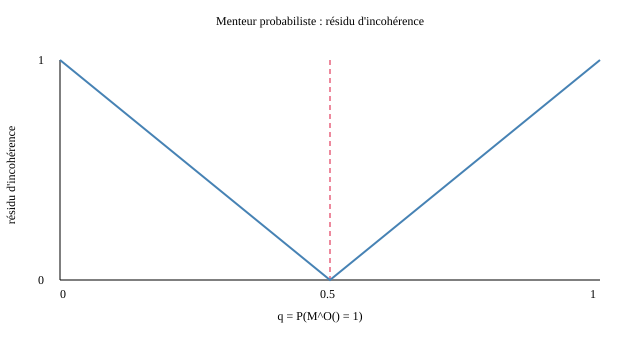

In [7]:
// Le résidu est calculé sur la même grille de 2001 points que la source.
double residu_incoherence(double q) => Math.Abs(q - (1.0 - q));
var qs = Enumerable.Range(0, 2001).Select(i => i / 2000.0).ToArray();
var residus = qs.Select(residu_incoherence).ToArray();
int idx_min = Enumerable.Range(0, qs.Length).OrderBy(i => residus[i]).First();
VerifierProche(qs[idx_min], 0.5, TOL, "Minimum inattendu");
VerifierProche(residus[idx_min], 0.0, TOL, "Résidu minimum inattendu");
VerifierProche(residu_incoherence(0.4), 0.2, TOL, "Résidu en 0.4 inattendu");
VerifierProche(residu_incoherence(0.6), 0.2, TOL, "Résidu en 0.6 inattendu");
Verifier(Enumerable.Range(0, qs.Length).All(i => i == idx_min || residus[i] > 0), "Minimum non unique sur la grille");
Console.WriteLine($"q* minimiseur sur la grille      : {qs[idx_min]:F6}");
Console.WriteLine($"residu en q*                    : {residus[idx_min].ToString("0.000e+00", CultureInfo.InvariantCulture)}");
Console.WriteLine($"residu en q=0.4                 : {residu_incoherence(0.4):F6}");
Console.WriteLine($"residu en q=0.6                 : {residu_incoherence(0.6):F6}");
Console.WriteLine();
Console.WriteLine("VERDICT 3b : l'unique solution coherente est q = 1/2 -- le residu est");
Console.WriteLine("            nul en q*, strictement positif ailleurs : le critere discrimine.");

// La figure vectorielle reprend les points calculés sur la grille.
var pointsSvg = string.Join(" ", qs.Select((q, i) => string.Format(CultureInfo.InvariantCulture, "{0:F2},{1:F2}", 60 + 540 * q, 280 - 220 * residus[i])));
var svg = $"<svg xmlns='http://www.w3.org/2000/svg' width='640' height='340' viewBox='0 0 640 340'><rect width='640' height='340' fill='white'/><text x='320' y='25' text-anchor='middle'>Menteur probabiliste : résidu d'incohérence</text><line x1='60' y1='280' x2='600' y2='280' stroke='black'/><line x1='60' y1='60' x2='60' y2='280' stroke='black'/><line x1='330' y1='60' x2='330' y2='280' stroke='crimson' stroke-dasharray='5 4'/><polyline points='{pointsSvg}' fill='none' stroke='steelblue' stroke-width='2'/><text x='320' y='320' text-anchor='middle'>q = P(M^O() = 1)</text><text x='15' y='175' transform='rotate(-90 15 175)' text-anchor='middle'>résidu d'incohérence</text><text x='60' y='298'>0</text><text x='320' y='298'>0.5</text><text x='590' y='298'>1</text><text x='38' y='284'>0</text><text x='38' y='64'>1</text></svg>";
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Graphique>((g, writer) => writer.Write(g.Svg), "image/svg+xml");
display(new Graphique(svg), "image/svg+xml");

class Graphique
{
    public string Svg { get; }
    public Graphique(string svg) { Svg = svg; }
}

Le résidu s'annule **exactement** en `q = 1/2` et croît linéairement de part et d'autre — il n'y a **pas** d'autre candidat. C'est la signature d'une condition qui discrimine : elle aurait pu s'annuler sur un plateau (critère mou) ou nulle part (contradiction même en randomisé) ; elle fait ni l'un ni l'autre.

Reste à confirmer que ce point théorique est bien celui qu'un tirage aléatoire honnête reproduit.

In [8]:
// Verification empirique : Bernoulli(1/2), n = 10 000, intervalle 3-sigma.
// xorshift64* ne peut pas utiliser l'etat nul : la graine declaree 0 est
// representee par cette constante non nulle, de facon deterministe.
ulong etat_xorshift = SEED == 0 ? 0x9E3779B97F4A7C15UL : unchecked((ulong)SEED);
ulong prochain_xorshift64star()
{
    etat_xorshift ^= etat_xorshift >> 12;
    etat_xorshift ^= etat_xorshift << 25;
    etat_xorshift ^= etat_xorshift >> 27;
    return unchecked(etat_xorshift * 2685821657736338717UL);
}
int n = 10_000;
var echantillon = Enumerable.Range(0, n)
    .Select(_ => (int)(prochain_xorshift64star() >> 63)).ToArray();
double moyenne = echantillon.Average();
double se = Math.Sqrt(0.25 / n);
double borne_inf = 0.5 - 3 * se, borne_sup = 0.5 + 3 * se;
bool dans_intervalle = borne_inf <= moyenne && moyenne <= borne_sup;
// Moyenne citee de la sortie Python : ce ne sont pas les tirages C#.
double moyenne_python_citee = 0.5030;
// Comparaison de deux moyennes stochastiques : tolerance de trois erreurs-types
// pour leur difference, sous le modele de deux echantillons independants.
double tolerance_ecart_moyennes = 3 * Math.Sqrt(2) * se;
double ecart_moyennes = moyenne - moyenne_python_citee;
Verifier(n == 10000 && echantillon.All(x => x == 0 || x == 1), "Échantillon invalide");
VerifierProche(se, 0.005, TOL, "Erreur standard inattendue");
VerifierProche(borne_inf, 0.485, TOL, "Borne inférieure inattendue");
VerifierProche(borne_sup, 0.515, TOL, "Borne supérieure inattendue");
Verifier(dans_intervalle, "Moyenne empirique hors de l'intervalle à trois écarts-types");
Verifier(Math.Abs(ecart_moyennes) <= tolerance_ecart_moyennes, "Écart des moyennes supérieur à la tolérance déclarée");
Console.WriteLine("Graine 0, générateur xorshift64* : les tirages diffèrent de ceux de NumPy.");
Console.WriteLine($"n = {n}");
Console.WriteLine($"moyenne empirique C# = {moyenne:F4}");
Console.WriteLine($"moyenne Python citée = {moyenne_python_citee:F4} ; écart C# - Python = {ecart_moyennes:+0.0000;-0.0000;0.0000}");
Console.WriteLine($"tolérance de comparaison des moyennes = {tolerance_ecart_moyennes:F4} ; écart dans la tolérance = {Math.Abs(ecart_moyennes) <= tolerance_ecart_moyennes}");
Console.WriteLine($"SE = sqrt(p(1-p)/n) = {se:F4}");
Console.WriteLine($"intervalle 3-sigma = [{borne_inf:F4}, {borne_sup:F4}]");
Console.WriteLine($"VERDICT 3c : moyenne dans l'intervalle -> {dans_intervalle} ({(dans_intervalle ? "OK" : "BIAIS")})");

Graine 0, générateur xorshift64* : les tirages diffèrent de ceux de NumPy.


n = 10000


moyenne empirique C# = 0.5092


moyenne Python citée = 0.5030 ; écart C# - Python = +0.0062


tolérance de comparaison des moyennes = 0.0212 ; écart dans la tolérance = True


SE = sqrt(p(1-p)/n) = 0.0050


intervalle 3-sigma = [0.4850, 0.5150]


VERDICT 3c : moyenne dans l'intervalle -> True (OK)


### Exercice 3 — Généraliser le menteur

Considère formellement le résidu associé à l'équation `q = a − q`, pour `q ∈ [0, 1]`.

Complète la cellule ci-dessous pour :

1. écrire `residu_generalise(a, q)` renvoyant `|q − (a − q)|` ;
2. balayer `q` sur `[0, 1]` pour `a = 0.5` puis `a = 1.5`, et localiser les minimiseurs ;
3. comparer ces minimiseurs aux solutions de l'équation et vérifier leur appartenance à `[0, 1]`.

La source affirme que `0.75` est hors de `[0, 1]` et conclut à une absence de solution pour `a = 1.5` : vérifie cette affirmation plutôt que de la reprendre. Distingue aussi la résolution de l'équation réelle de l'interprétation probabiliste de `M^O() = a − O(M^O, b)`, qui impose des conditions supplémentaires sur ses valeurs possibles.

**Critère d'acceptation** : la cellule affiche le minimiseur pour chaque valeur de `a`, son résidu et une conclusion explicite sur l'équation dans `[0, 1]`.

In [9]:
// Exercice 3 -- a completer.
// TODO etudiant : generaliser le residu du menteur a M^O() = a - O(M^O, b).
double? residu_generalise(double a, double q)
{
    return null;
}
var grille_exo3 = Enumerable.Range(0, 2001).Select(i => i / 2000.0).ToArray();
foreach (double a in new[] { 0.5, 1.5 })
{
    // TODO : calculer le residu sur la grille, trouver l'indice du minimum,
    // et conclure q* = a/2 (ou AUCUNE SOLUTION COHERENTE DANS [0,1]).
    Console.WriteLine($"a={a.ToString("0.0", CultureInfo.InvariantCulture)}  -- TODO localiser le minimiseur et conclure");
}
Console.WriteLine("Exercice 3 a completer : generaliser la solution coherente q = a/2.");

a=0.5  -- TODO localiser le minimiseur et conclure


a=1.5  -- TODO localiser le minimiseur et conclure


Exercice 3 a completer : generaliser la solution coherente q = a/2.


## 4. Théorème 3.1 — Décision causale et oracle utilitaire

Le théorème 3.1 de l'article énonce qu'on peut encoder une comparaison d'utilités `U(a) > U(b)` comme une requête d'oracle `(M_U, p)` où `M_U` est une machine qui implémente la théorie causale de la décision. L'action choisie par l'agent maximisera l'utilité espérée.

Le théorème 3.1 énonce qu'une comparaison d'utilités `U(a) > U(b)` peut être **encodée comme une requête d'oracle** `(M_U, p)`, où `M_U` est une machine qui implémente la théorie causale de la décision (CDT) : l'agent traite **sa propre action comme causalement indépendante** de la prédiction que l'oracle fait de lui. L'action choisie maximise alors l'utilité espérée *selon CDT*.

**Le contenu discriminant est l'écart CDT / EDT.** La théorie évidentielle (EDT) conditionne sur l'**évidence** que son propre choix apporte sur le choix de l'autre. Dans un jeu corrélé, les deux théories peuvent désigner des actions **différentes** — c'est exactement ce que l'encodage doit rendre visible.

Jeu-jouet : **chasse au cerf** (Stag Hunt) avec corrélation entre les joueurs.

| | Cerf (0) | Lièvre (1) |
|---|---|---|
| **Cerf (0)** | (4, 4) | (0, 2) |
| **Lièvre (1)** | (2, 0) | (2, 2) |

Le jouet est délibérément **non dégénéré** : le paiement de Lièvre pour Ligne est constant (2), donc CDT et EDT ne peuvent différer que par la **probabilité conditionnelle** `c₁ = P(autre joue Cerf | je joue Cerf)`, qui n'égale la marginale `b` que si les joueurs sont indépendants. C'est le couplage qui porte tout l'écart.

In [10]:
// Chasse au cerf : actions 0 = Cerf, 1 = Lievre.
var A_ST = new double[,] { { 4, 0 }, { 2, 2 } }; // utilites Ligne
var B_ST = new double[,] { { 4, 2 }, { 0, 2 } }; // utilites Colonne
var NOMS = new[] { "Cerf", "Lievre" };

// Distribution JOINTE (moi, autre) : marginale autre = 0.40, couplage fort.
// c1 = P(autre = Cerf | je Cerf) = 0.32/0.40 = 0.80 : l'evidence depasse la
// marginale -- c'est LE levier de l'ecart CDT/EDT.
var JOINTE = new double[,] { { 0.32, 0.08 }, { 0.08, 0.52 } };

double[] marginale_autre() => new[] { JOINTE[0, 0] + JOINTE[1, 0], JOINTE[0, 1] + JOINTE[1, 1] };
double conditionnelle_autre(int action) => JOINTE[action, 0] / (JOINTE[action, 0] + JOINTE[action, 1]);
double utilite_cdt(double[,] A, int action)
{
    var marginale = marginale_autre();
    return marginale[0] * A[action, 0] + marginale[1] * A[action, 1];
}
double utilite_edt(double[,] A, int action)
{
    double c = conditionnelle_autre(action);
    return c * A[action, 0] + (1 - c) * A[action, 1];
}

// Comparaison aux valeurs de référence pour chaque probabilité et chaque utilité.
VerifierProche(marginale_autre()[0], 0.4, TOL, "Marginale inattendue");
VerifierProche(marginale_autre()[1], 0.6, TOL, "Marginale complémentaire inattendue");
VerifierProche(conditionnelle_autre(0), 0.8, TOL, "Conditionnelle Cerf inattendue");
VerifierProche(conditionnelle_autre(1), 2.0 / 15.0, TOL, "Conditionnelle Lièvre inattendue");
var attentes_cdt = new[] { 1.6, 2.0 };
var attentes_edt = new[] { 3.2, 2.0 };
for (int a = 0; a < 2; a++)
{
    VerifierProche(utilite_cdt(A_ST, a), attentes_cdt[a], TOL, "Utilité CDT inattendue");
    VerifierProche(utilite_edt(A_ST, a), attentes_edt[a], TOL, "Utilité EDT inattendue");
}
Console.WriteLine($"marginale P(autre = Cerf)           b  = {marginale_autre()[0]:F4}");
Console.WriteLine($"conditionnelle P(autre | je Cerf)   c1 = {conditionnelle_autre(0):F4}");
Console.WriteLine($"conditionnelle P(autre | je Lievre) c0 = {conditionnelle_autre(1):F4}");
Console.WriteLine();
Console.WriteLine($"{"action",18}{"U_CDT",10}{"U_EDT",10}");
for (int a = 0; a < 2; a++)
    Console.WriteLine($"{NOMS[a],18}{utilite_cdt(A_ST, a),10:F4}{utilite_edt(A_ST, a),10:F4}");
int choix_cdt = utilite_cdt(A_ST, 1) > utilite_cdt(A_ST, 0) ? 1 : 0;
int choix_edt = utilite_edt(A_ST, 1) > utilite_edt(A_ST, 0) ? 1 : 0;
Verifier(choix_cdt == 1 && choix_edt == 0, "Choix inattendus");
Console.WriteLine();
Console.WriteLine($"action choisie par CDT : {NOMS[choix_cdt]}");
Console.WriteLine($"action choisie par EDT : {NOMS[choix_edt]}");
Console.WriteLine($"VERDICT 4 : les deux theories divergent -> {choix_cdt != choix_edt}");
Console.WriteLine();
Console.WriteLine("Lecture : la marginale b = 0.4 fait preferer STRICTEMENT Lievre a CDT");
Console.WriteLine("(U_CDT(Cerf) = 4b = 1.6 < 2 = U_CDT(Lievre)). Mais le couplage");
Console.WriteLine("c1 = 0.8 > 0.5 porte U_EDT(Cerf) a 3.2 > 2 -> EDT prefere Cerf.");
Console.WriteLine("Les deux theories designent des actions OPPOSEES : la meme requete,");
Console.WriteLine("deux theories de la decision, deux reponses -- l'ecart est reel.");

marginale P(autre = Cerf)           b  = 0.4000


conditionnelle P(autre | je Cerf)   c1 = 0.8000


conditionnelle P(autre | je Lievre) c0 = 0.1333


            action     U_CDT     U_EDT


              Cerf    1.6000    3.2000


            Lievre    2.0000    2.0000


... (4 outputs left out)

(U_CDT(Cerf) = 4b = 1.6 < 2 = U_CDT(Lievre)). Mais le couplage


c1 = 0.8 > 0.5 porte U_EDT(Cerf) a 3.2 > 2 -> EDT prefere Cerf.


Les deux theories designent des actions OPPOSEES : la meme requete,


deux theories de la decision, deux reponses -- l'ecart est reel.


L'écart est net : sur la marginale `b = 0.4`, CDT **strictement préfère Lièvre** (`U_CDT(Cerf) = 1.6 < 2`) ; la corrélation `c₁ = 0.8` élève l'espérance conditionnelle d'EDT à `3.2`, qui fait **préférer Cerf**. Les deux théories désignent des actions **opposées** — et la divergence est entièrement portée par le couplage, pas par les paiements.

C'est précisément ce que l'encodage du théorème 3.1 doit capturer.

In [11]:
// Encodage de la comparaison U(a) > U(b) comme REQUETE D'ORACLE (theoreme 3.1).
DeterministicMachine machine_utilite(double[,] A, int a, int b_action, string theorie)
{
    // La réponse vaut 1 exactement quand l'écart d'utilité dépasse le seuil.
    Func<double[,], int, double> u = theorie == "cdt" ? utilite_cdt : utilite_edt;
    return new DeterministicMachine($"U_{theorie}({a})>U_{theorie}({b_action})",
        (rep, p) => u(A, a) - u(A, b_action) > p ? 1 : 0);
}
Console.WriteLine("Encodage de U(Cerf) > U(Lievre) en requete (M_U, p), seuil p = 0 :");
foreach (string theorie in new[] { "cdt", "edt" })
{
    var M_U = machine_utilite(A_ST, 0, 1, theorie);
    var reponse = new ReflexiveQuery(M_U, 0.0, N_QUERIES_MAX, N_APPELS).Answer();
    Func<double[,], int, double> u = theorie == "cdt" ? utilite_cdt : utilite_edt;
    double ecart = u(A_ST, 0) - u(A_ST, 1);
    double attendu = theorie == "cdt" ? -0.4 : 1.2;
    int reponse_attendue = theorie == "cdt" ? 0 : 1;
    VerifierProche(ecart, attendu, TOL, "Écart d'utilité inattendu");
    Verifier(reponse == reponse_attendue && reponse == (ecart > 0 ? 1 : 0), "Réponse d'oracle inattendue");
    Console.WriteLine($"  {theorie.ToUpperInvariant(),-4} O(M_U, 0) = {reponse}   (ecart U = {ecart.ToString("+0.0000;-0.0000;+0.0000", CultureInfo.InvariantCulture)})");
}
Console.WriteLine();
Console.WriteLine("VERDICT 4b : la comparaison est encodee en requete -- l'oracle repond 1");
Console.WriteLine("             ssi l'ecart d'utilite est strictement positif au seuil p.");
Console.WriteLine();
Console.WriteLine("Honnêteté : ceci illustre l'ENCODAGE sur un jouet fini. Le theoreme 3.1");
Console.WriteLine("porte sur la construction generale ; la restriction finie est l'objet de");
Console.WriteLine("la section 6. Un encodage qui reussit sur un jouet ne prouve pas le");
Console.WriteLine("theoreme -- il le rend visible.");

Encodage de U(Cerf) > U(Lievre) en requete (M_U, p), seuil p = 0 :


  CDT  O(M_U, 0) = 0   (ecart U = -0.4000)


  EDT  O(M_U, 0) = 1   (ecart U = +1.2000)


VERDICT 4b : la comparaison est encodee en requete -- l'oracle repond 1


             ssi l'ecart d'utilite est strictement positif au seuil p.


Honnêteté : ceci illustre l'ENCODAGE sur un jouet fini. Le theoreme 3.1


porte sur la construction generale ; la restriction finie est l'objet de


la section 6. Un encodage qui reussit sur un jouet ne prouve pas le


theoreme -- il le rend visible.


### Exercice 4 — Le couplage qui inverse la décision

Dans la section 4, le couplage `c₁ = 0.8` fait choisir **Cerf** à EDT alors que CDT, sur la marginale `b = 0.4`, choisit **Lièvre**. Le couplage contrôle entièrement la décision d'EDT.

Complète la cellule ci-dessous pour :

1. construire une famille de distributions jointes `jointe_couplee(ρ)` à marginales **fixes** à `1/2` et de couplage `ρ ∈ [0, 1]` (`ρ = 0` : joueurs indépendants ; `ρ = 1` : parfaitement corrélés),
2. pour chaque `ρ`, calculer `c₁`, `U_EDT(Cerf)`, `U_EDT(Lièvre)` et l'**action choisie par EDT**,
3. **identifier le seuil `ρ*`** à partir duquel EDT bascule, et vérifier que CDT ne bouge **jamais**.

**Indice** : une paramétrisation valide des probabilités jointes est `P(les deux = Cerf) = P(les deux = Lièvre) = (1+ρ)/4` et `P(désaccord) = (1−ρ)/4` pour chacun des deux désaccords ; les marginales restent `1/2`. Le seuil s'obtient en résolvant `U_EDT(Cerf) = U_EDT(Lièvre)`.

**Critère d'acceptation** : la cellule imprime le tableau `ρ → c₁ → action EDT`, affiche `ρ*`, et conclut que l'action CDT est **invariante** en `ρ`.

In [12]:
// Exercice 4 -- a completer.
// TODO etudiant : parametrer la jointe par un couplage rho, balayer rho, et
// montrer que EDT bascule alors que CDT est invariant.
double[,] jointe_couplee(double rho)
{
    return null; // TODO : renvoyer une matrice 2x2 de probabilites
}
for (int i = 0; i <= 5; i++)
{
    double rho = i / 5.0;
    // TODO : calculer c1, U_EDT(Cerf), U_EDT(Lievre), l'action choisie par EDT,
    // et verifier que l'action CDT ne depend pas de rho.
    Console.WriteLine($"rho={rho:F2}  -- TODO calculer et comparer CDT vs EDT");
}
Console.WriteLine("Exercice 4 a completer : identifier le seuil rho* et l'invariance de CDT.");

rho=0.00  -- TODO calculer et comparer CDT vs EDT


rho=0.20  -- TODO calculer et comparer CDT vs EDT


rho=0.40  -- TODO calculer et comparer CDT vs EDT


rho=0.60  -- TODO calculer et comparer CDT vs EDT


rho=0.80  -- TODO calculer et comparer CDT vs EDT


rho=1.00  -- TODO calculer et comparer CDT vs EDT


Exercice 4 a completer : identifier le seuil rho* et l'invariance de CDT.


## 5. Théorème 4.1 — Agents intégrés et équilibre de Nash

Si les agents d'un jeu sont *intégrés* — c'est-à-dire si leurs probabilités d'action sont les réponses à des requêtes d'oracle cohérentes — alors le profil agrégé est un équilibre de Nash du jeu sous-jacent.

Si les agents d'un jeu sont **intégrés** — c'est-à-dire si leurs probabilités d'action sont les réponses à des requêtes d'oracle **cohérentes** — alors le profil agrégé est un **équilibre de Nash** du jeu sous-jacent.

Le vérificateur ci-dessous est **indépendant de tout solveur** : il recalcule les écarts unilatéraux purs directement sur les matrices de paiement du jeu sous-jacent. Un profil est un équilibre de Nash si et seulement si **aucun** joueur n'a de déviation pure unilatérale qui augmente strictement son espérance.

**Deux exigences pour que la vérification ait du sens** : le vérificateur doit **accepter** un profil intégré (un équilibre) et **rejeter** un profil non intégré (une paire de mixtures arbitraires). Les deux cas sont exécutés — accepter tout le temps serait une tautologie.

In [13]:
// Vérification indépendante par calcul direct des gains de déviation.
(bool ok, double uL, double uC, double gainL, double gainC) is_nash(double[] pL, double[] pC, double[,] A, double[,] B, double tol = TOL)
{
    int m = A.GetLength(0), nColonnes = A.GetLength(1);
    var devL = new double[m];
    var devC = new double[nColonnes];
    for (int i = 0; i < m; i++)
        for (int j = 0; j < nColonnes; j++)
        {
            devL[i] += A[i, j] * pC[j];
            devC[j] += pL[i] * B[i, j];
        }
    double uL = Enumerable.Range(0, m).Sum(i => pL[i] * devL[i]);
    double uC = Enumerable.Range(0, nColonnes).Sum(j => pC[j] * devC[j]);
    double gainL = devL.Max() - uL, gainC = devC.Max() - uC;
    bool simplex = pL.All(x => x >= -tol) && pC.All(x => x >= -tol)
        && Math.Abs(pL.Sum() - 1) <= tol && Math.Abs(pC.Sum() - 1) <= tol;
    return (simplex && gainL <= tol && gainC <= tol, uL, uC, gainL, gainC);
}

// Élimination de Gauss avec pivot : un système singulier ne fournit pas de candidat isolé.
double[] resoudre_systeme(double[,] coefficients, double[] second)
{
    int n = second.Length;
    var a = (double[,])coefficients.Clone();
    var b = (double[])second.Clone();
    for (int k = 0; k < n; k++)
    {
        int pivot = k;
        for (int i = k + 1; i < n; i++) if (Math.Abs(a[i, k]) > Math.Abs(a[pivot, k])) pivot = i;
        if (Math.Abs(a[pivot, k]) < 1e-10) return null;
        for (int j = 0; j < n; j++) { double t = a[k, j]; a[k, j] = a[pivot, j]; a[pivot, j] = t; }
        double tb = b[k]; b[k] = b[pivot]; b[pivot] = tb;
        double d = a[k, k];
        for (int j = k; j < n; j++) a[k, j] /= d;
        b[k] /= d;
        for (int i = 0; i < n; i++) if (i != k)
        {
            double f = a[i, k];
            for (int j = k; j < n; j++) a[i, j] -= f * a[k, j];
            b[i] -= f * b[k];
        }
    }
    return b;
}

// Énumération des supports de même taille : indifférence, normalisation puis vérification indépendante.
List<(double[] L, double[] C)> enumerer_supports(double[,] A, double[,] B)
{
    int m = A.GetLength(0), n = A.GetLength(1);
    var resultats = new List<(double[] L, double[] C)>();
    for (int taille = 1; taille <= Math.Min(m, n); taille++)
    for (int masqueL = 1; masqueL < (1 << m); masqueL++)
    {
        var lignes = Enumerable.Range(0, m).Where(i => (masqueL & (1 << i)) != 0).ToArray();
        if (lignes.Length != taille) continue;
        for (int masqueC = 1; masqueC < (1 << n); masqueC++)
        {
            var colonnes = Enumerable.Range(0, n).Where(j => (masqueC & (1 << j)) != 0).ToArray();
            if (colonnes.Length != taille) continue;
            var matC = new double[taille, taille];
            var matL = new double[taille, taille];
            var rhs = new double[taille];
            for (int k = 0; k < taille - 1; k++)
                for (int v = 0; v < taille; v++)
                {
                    matC[k, v] = A[lignes[k + 1], colonnes[v]] - A[lignes[0], colonnes[v]];
                    matL[k, v] = B[lignes[v], colonnes[k + 1]] - B[lignes[v], colonnes[0]];
                }
            for (int v = 0; v < taille; v++) { matC[taille - 1, v] = 1; matL[taille - 1, v] = 1; }
            rhs[taille - 1] = 1;
            var solutionC = resoudre_systeme(matC, rhs);
            var solutionL = resoudre_systeme(matL, rhs);
            if (solutionL == null || solutionC == null || solutionL.Any(x => x <= 1e-10) || solutionC.Any(x => x <= 1e-10)) continue;
            var pL = new double[m]; var pC = new double[n];
            for (int v = 0; v < taille; v++) { pL[lignes[v]] = solutionL[v]; pC[colonnes[v]] = solutionC[v]; }
            if (is_nash(pL, pC, A, B).ok) resultats.Add((pL, pC));
        }
    }
    return resultats;
}
string afficher_vecteur(double[] p) => "[" + string.Join(" ", p.Select(x => Math.Abs(x - Math.Round(x)) < 1e-10 ? x.ToString("0.", CultureInfo.InvariantCulture) : x.ToString("0.####", CultureInfo.InvariantCulture))) + "]";
string scientifique(double x) => x.ToString("0.00e+00", CultureInfo.InvariantCulture);

// Equilibres du jeu sous-jacent, pour situer le profil integre.
var equilibres_st = enumerer_supports(A_ST, B_ST);
var references_st = new[] { new[] { 1.0, 0.0 }, new[] { 0.0, 1.0 }, new[] { 0.5, 0.5 } };
Verifier(equilibres_st.Count == references_st.Length, "Nombre d'équilibres de la chasse au cerf inattendu");
foreach (var reference in references_st)
    Verifier(equilibres_st.Any(e => e.L.Zip(reference, (x, y) => Math.Abs(x - y)).Max() <= TOL && e.C.Zip(reference, (x, y) => Math.Abs(x - y)).Max() <= TOL), "Équilibre Python cité non retrouvé");
Console.WriteLine("Equilibres de Nash de la chasse au cerf (support_enumeration) :");
for (int i = 0; i < equilibres_st.Count; i++)
{
    var e = equilibres_st[i]; var det = is_nash(e.L, e.C, A_ST, B_ST);
    Console.WriteLine($"  [{i}] L={afficher_vecteur(e.L)} C={afficher_vecteur(e.C)}  uL={det.uL:F4} uC={det.uC:F4}  Nash={det.ok}");
}
Console.WriteLine();
// Profil INTEGRE : l'equilibre completement mixte, dont les probabilites sont
// exactement celles qu'un oracle reflexif coherent doit produire pour rendre
// les agents indifferents entre leurs deux actions.
int idx_mixte = Enumerable.Range(0, equilibres_st.Count).OrderByDescending(i => equilibres_st[i].L.Count(x => x > 1e-12) + equilibres_st[i].C.Count(x => x > 1e-12)).First();
var pi_L_integre = equilibres_st[idx_mixte].L;
var pi_C_integre = equilibres_st[idx_mixte].C;
var det_int = is_nash(pi_L_integre, pi_C_integre, A_ST, B_ST);
Verifier(det_int.ok, "Profil intégré rejeté");
VerifierProche(det_int.uL, 2, TOL, "Utilité intégrée Ligne inattendue");
VerifierProche(det_int.uC, 2, TOL, "Utilité intégrée Colonne inattendue");
Console.WriteLine($"Profil INTEGRE (equilibre completement mixte, [{idx_mixte}]) : L={afficher_vecteur(pi_L_integre)} C={afficher_vecteur(pi_C_integre)}");
Console.WriteLine($"  uL={det_int.uL:F4}  uC={det_int.uC:F4}  gain_dev_L_max={scientifique(det_int.gainL)}  gain_dev_C_max={scientifique(det_int.gainC)}");
Console.WriteLine($"  Nash -> {det_int.ok}");
Console.WriteLine();
// Contre-epreuve : un profil NON integre (mixtures arbitraires) doit etre REJETE.
var pi_L_brut = new[] { 0.30, 0.70 };
var pi_C_brut = new[] { 0.80, 0.20 };
var det_brut = is_nash(pi_L_brut, pi_C_brut, A_ST, B_ST);
Verifier(!det_brut.ok, "Profil arbitraire accepté");
VerifierProche(det_brut.gainL, 0.84, TOL, "Gain de déviation Ligne inattendu");
VerifierProche(det_brut.gainC, 0.64, TOL, "Gain de déviation Colonne inattendu");
Console.WriteLine($"Profil NON integre (arbitraire) : L={afficher_vecteur(pi_L_brut)} C={afficher_vecteur(pi_C_brut)}");
Console.WriteLine($"  gain_dev_L_max={det_brut.gainL.ToString("+0.0000;-0.0000;+0.0000", CultureInfo.InvariantCulture)}  gain_dev_C_max={det_brut.gainC.ToString("+0.0000;-0.0000;+0.0000", CultureInfo.InvariantCulture)}");
Console.WriteLine($"  Nash -> {det_brut.ok}");
Console.WriteLine();
Console.WriteLine($"VERDICT 5 : integre -> {det_int.ok} ; non integre -> {det_brut.ok}");
Console.WriteLine("            (le verificateur REJETTE le profil arbitraire -> il a des dents)");
Console.WriteLine();
Console.WriteLine("Conformement au theoreme 4.1 : les probabilites issues d'oracles");
Console.WriteLine("coherents forment un equilibre de Nash ; des mixtures quelconques, non.");

Equilibres de Nash de la chasse au cerf (support_enumeration) :


  [0] L=[1 0] C=[1 0]  uL=4.0000 uC=4.0000  Nash=True


  [1] L=[0 1] C=[0 1]  uL=2.0000 uC=2.0000  Nash=True


  [2] L=[0.5 0.5] C=[0.5 0.5]  uL=2.0000 uC=2.0000  Nash=True


Profil INTEGRE (equilibre completement mixte, [2]) : L=[0.5 0.5] C=[0.5 0.5]


  uL=2.0000  uC=2.0000  gain_dev_L_max=0.00e+00  gain_dev_C_max=0.00e+00


... (4 outputs left out)

VERDICT 5 : integre -> True ; non integre -> False


            (le verificateur REJETTE le profil arbitraire -> il a des dents)


Conformement au theoreme 4.1 : les probabilites issues d'oracles


coherents forment un equilibre de Nash ; des mixtures quelconques, non.


## 6. Restriction finie (théorème 5.1) et jeu auxiliaire

Le théorème 5.1 donne une **restriction finie, fermée et bornée** des requêtes autorisées :

- *Finie* : un ensemble fini de paires `(M, p)` est autorisé (par exemple `N_QUERIES_MAX`).
- *Fermée* : toute réponse d'un oracle dans la restriction est elle-même une requête autorisée.
- *Bornée* : la profondeur d'imbrication des requêtes est bornée (au plus une profondeur `D`).

Le théorème 5.1 donne une **restriction finie, fermée et bornée** des requêtes autorisées. Les trois propriétés sont ici **déclarées puis mesurées**, pas affirmées :

- ***Finie*** : un ensemble **explicite** de requêtes `Q = {(M, p)}` est autorisé, avec `|Q| ≤ N_QUERIES_MAX` — le cardinal est compté.
- ***Fermée*** : la règle de requête suivante — après une réponse `b`, on ré-interroge à la croyance mise à jour `(p+b)/2` arrondie sur la grille — **reste dans `Q`**. La fermeture est vérifiée par **énumération exhaustive** des requêtes atteignables jusqu'à `DEPTH_MAX`.
- ***Bornée*** : la profondeur d'imbrication est bornée par `DEPTH_MAX`, et le **nombre d'appels à l'oracle est compté** puis comparé à `N_QUERIES_MAX`.

On construit alors un **jeu auxiliaire** dont les stratégies pures sont les **programmes** autorisés par la restriction — chacun étant une meilleure réponse pure à une croyance fixée sur la grille. Résolu par **énumération des supports en BCL**, un équilibre du jeu auxiliaire induit une distribution d'**actions** sur le jeu sous-jacent.

**La contrainte de réflexivité est ici une vraie condition, pas un théorème gratuit.** Chaque programme consulté (masse positive) porte une croyance `c` sur l'action de l'adversaire ; le profil induit fait *réellement* jouer l'action 0 à l'adversaire avec une certaine probabilité `π[0]`. La **cohérence réflexive** exige `c = π[0]` — la croyance doit être **auto-realisateur**. Un programme dont la croyance ne correspond pas au profil qu'il contribue à produire est réflexivement **incohérent**.

**Le vérificateur indépendant est le cœur de la section.** Il ne réutilise ni l'énumération des supports ni la construction du jeu auxiliaire : à partir des seules mixtures déclarées, il recalcule (a) le **résidu réflexif** (croyance vs profil induit), (b) la validité des simplexes, (c) les **écarts unilatéraux purs**. Et pour prouver qu'il discrimine, on lui soumet une version **perturbée** de la solution — qu'il doit **rejeter**.

In [14]:
// ---- 1. Restriction : finie, fermee, bornee -------------------------------
DeterministicMachine programme_a_croyance(double[,] A, double croyance)
{
    string texte = croyance.ToString("0.0#", CultureInfo.InvariantCulture);
    return new DeterministicMachine($"BR(c={texte})", (rep, p) =>
    {
        double u0 = croyance * A[0, 0] + (1 - croyance) * A[0, 1];
        double u1 = croyance * A[1, 0] + (1 - croyance) * A[1, 1];
        return u1 > u0 ? 1 : 0;
    });
}
var CROYANCES = new[] { 0.0, 0.25, 0.5, 0.75, 1.0 };
var PROBAS = new[] { 0.0, 0.25, 0.5, 0.75, 1.0 };
var PROGRAMMES = CROYANCES.Select(c => programme_a_croyance(A_ST, c)).ToArray();
var RESTRICTION = (from machine in PROGRAMMES from p in PROBAS select (machine, p)).ToArray();
int? oracle_reponse(IMachine machine, double p) => new ReflexiveQuery(machine, p, N_QUERIES_MAX, N_APPELS).Answer();

// Le successeur arrondit sur la grille, en départageant vers la plus petite valeur.
(DeterministicMachine machine, double p) successeur(DeterministicMachine machine, double p)
{
    int? b = oracle_reponse(machine, p);
    Verifier(b.HasValue, "Borne de requête atteinte pendant la fermeture");
    double cible = (p + b.Value) / 2.0;
    return (machine, PROBAS.OrderBy(x => Math.Abs(x - cible)).ThenBy(x => x).First());
}
int appels_avant = N_APPELS["oracle"];
var atteignables = new HashSet<(DeterministicMachine machine, double p)>();
var frontiere = RESTRICTION.ToList();
for (int profondeur = 0; profondeur < DEPTH_MAX; profondeur++)
{
    frontiere = frontiere.Select(r => successeur(r.machine, r.p)).ToList();
    foreach (var r in frontiere) atteignables.Add(r);
}
int appels_fermeture = N_APPELS["oracle"] - appels_avant;
bool ferme = atteignables.All(r => RESTRICTION.Contains(r));
Verifier(PROGRAMMES.Length == 5 && PROBAS.Length == 5 && RESTRICTION.Length == 25, "Cardinal de restriction inattendu");
Verifier(atteignables.Count == 15 && ferme, "Fermeture inattendue");
Verifier(appels_fermeture == 50 && appels_fermeture <= N_QUERIES_MAX, "Nombre d'appels inattendu");
Console.WriteLine($"|PROGRAMMES| = {PROGRAMMES.Length}   |PROBAS| = {PROBAS.Length}");
Console.WriteLine($"|Q| = {RESTRICTION.Length}   (borne N_QUERIES_MAX = {N_QUERIES_MAX} ; respectee -> {RESTRICTION.Length <= N_QUERIES_MAX})");
Console.WriteLine();
Console.WriteLine($"requetes atteignables (depth <= {DEPTH_MAX})      : {atteignables.Count}");
Console.WriteLine($"toutes incluses dans Q (FERMETURE)               : {ferme}");
Console.WriteLine($"appels oracle consommes par l'enumeration        : {appels_fermeture} / {N_QUERIES_MAX}  (respectee -> {appels_fermeture <= N_QUERIES_MAX})");
Console.WriteLine();
Console.WriteLine($"VERDICT 6a : finie={RESTRICTION.Length <= N_QUERIES_MAX}  fermee={ferme}  bornee={appels_fermeture <= N_QUERIES_MAX}");

|PROGRAMMES| = 5   |PROBAS| = 5


|Q| = 25   (borne N_QUERIES_MAX = 64 ; respectee -> True)


requetes atteignables (depth <= 2)      : 15


toutes incluses dans Q (FERMETURE)               : True


appels oracle consommes par l'enumeration        : 50 / 64  (respectee -> True)


VERDICT 6a : finie=True  fermee=True  bornee=True


Les trois propriétés sont **mesurées** : `|Q| = 25` sous la borne, l'énumération exhaustive des requêtes atteignables reste dans `Q` (fermeture), et l'énumération elle-même a coûté exactement `25 × 2 = 50` appels d'oracle, sous la borne de 64. Rien n'est affirmé — tout est compté.

La restriction étant posée, construisons le jeu auxiliaire qu'elle autorise.

In [15]:
// ---- 2. Jeu auxiliaire sur la restriction, résolu en BCL ------------------
int K = PROGRAMMES.Length;
var A_aux = new double[K, K];
var B_aux = new double[K, K];
for (int i = 0; i < K; i++)
    for (int j = 0; j < K; j++)
    {
        int aL = oracle_reponse(PROGRAMMES[i], 0.5).Value;
        int aC = oracle_reponse(PROGRAMMES[j], 0.5).Value;
        A_aux[i, j] = A_ST[aL, aC];
        B_aux[i, j] = B_ST[aL, aC];
    }
Console.WriteLine("Actions jouees par chaque programme (requete d'ancrage p = 0.5) :");
var actions_attendues = new[] { 1, 1, 0, 0, 0 };
for (int i = 0; i < K; i++)
{
    int action = oracle_reponse(PROGRAMMES[i], 0.5).Value;
    Verifier(action == actions_attendues[i], "Action de programme inattendue");
    Console.WriteLine($"  [{i}] {PROGRAMMES[i].Representation(),-14} -> action {action}  ({NOMS[action]})");
}
Console.WriteLine();
var equilibres_aux = enumerer_supports(A_aux, B_aux);
// Référence citée : nombre de candidats imprimé par le jumeau Python.
Verifier(equilibres_aux.Count == 49, "Nombre d'équilibres auxiliaires différent de la référence Python citée");
Verifier(equilibres_aux.All(e => is_nash(e.L, e.C, A_aux, B_aux).ok), "Candidat auxiliaire non Nash");
Console.WriteLine($"equilibres du jeu auxiliaire : {equilibres_aux.Count}");

// Profil auxiliaire imprimé par le jumeau Python en cellule 34 : référence citée.
var reference_aux_L = new[] { 0.0, 0.0, 0.0, 0.0, 1.0 };
var reference_aux_C = new[] { 0.0, 0.0, 0.0, 0.0, 1.0 };
double ecart_reference_aux = equilibres_aux.Min(e => Math.Max(
    e.L.Zip(reference_aux_L, (x, y) => Math.Abs(x - y)).Max(),
    e.C.Zip(reference_aux_C, (x, y) => Math.Abs(x - y)).Max()));
Verifier(ecart_reference_aux <= TOL, "Profil auxiliaire Python cité non retrouvé");
Console.WriteLine($"Profil auxiliaire Python cité (cellule 34) : L={afficher_vecteur(reference_aux_L)} C={afficher_vecteur(reference_aux_C)}");
Console.WriteLine($"Écart maximal minimal au profil cité = {scientifique(ecart_reference_aux)} ; tolérance = {scientifique(TOL)}");

Actions jouees par chaque programme (requete d'ancrage p = 0.5) :


  [0] BR(c=0.0)      -> action 1  (Lievre)


  [1] BR(c=0.25)     -> action 1  (Lievre)


  [2] BR(c=0.5)      -> action 0  (Cerf)


  [3] BR(c=0.75)     -> action 0  (Cerf)


  [4] BR(c=1.0)      -> action 0  (Cerf)


equilibres du jeu auxiliaire : 49


Profil auxiliaire Python cité (cellule 34) : L=[0 0 0 0 1] C=[0 0 0 0 1]


Écart maximal minimal au profil cité = 0.00e+00 ; tolérance = 1.00e-09


Le jeu auxiliaire est construit **à partir des réponses réelles de la restriction** — chaque case de la matrice est le paiement du jeu sous-jacent aux actions que les deux programmes produisent à la requête d'ancrage `p = 0.5`. Rien n'est codé en dur : changer la grille des croyances changerait la matrice.

Résoudre ce jeu ne suffira pas : encore faut-il attester que la solution satisfait la contrainte réflexive — indépendamment du solveur.

In [16]:
// ---- 3. Verificateur INDEPENDANT des contraintes de reflexivite -----------
// La projection interroge les programmes, sans utiliser les matrices auxiliaires.
double[] profil_implemente(double[] mix_programmes)
{
    Verifier(mix_programmes.Length == PROGRAMMES.Length, "Dimension de mixture incorrecte");
    var pi = new double[2];
    for (int i = 0; i < PROGRAMMES.Length; i++)
    {
        int? action = oracle_reponse(PROGRAMMES[i], 0.5);
        Verifier(action.HasValue, "Réponse absente");
        pi[action.Value] += mix_programmes[i];
    }
    return pi;
}

double residu_reflexif(double[] mix_L, double[] mix_C, double[] pi_L, double[] pi_C)
{
    double r = 0;
    for (int i = 0; i < CROYANCES.Length; i++)
        r += mix_L[i] * Math.Abs(CROYANCES[i] - pi_C[0]) + mix_C[i] * Math.Abs(CROYANCES[i] - pi_L[0]);
    return r;
}

// Les mixtures doivent être des simplexes, y compris pour les composantes négatives.
(double[] piL, double[] piC, double resSimplexe, double resReflexif, bool nash, double uL, double uC, string verdict)
verificateur_reflexivite(double[] mix_L, double[] mix_C, double[,] A, double[,] B)
{
    var piL = profil_implemente(mix_L);
    var piC = profil_implemente(mix_C);
    double resSimplexe = Math.Abs(piL.Sum() - 1) + Math.Abs(piC.Sum() - 1);
    double resReflexif = residu_reflexif(mix_L, mix_C, piL, piC);
    var nash = is_nash(piL, piC, A, B);
    bool simplexValide = mix_L.All(x => !double.IsNaN(x) && !double.IsInfinity(x) && x >= -TOL)
        && mix_C.All(x => !double.IsNaN(x) && !double.IsInfinity(x) && x >= -TOL)
        && resSimplexe <= TOL;
    bool coherent = simplexValide && resReflexif <= TOL && nash.ok;
    return (piL, piC, resSimplexe, resReflexif, nash.ok, nash.uL, nash.uC, coherent ? "COHERENT" : "INCOHERENT");
}

Console.WriteLine($"Verification de CHAQUE equilibre du jeu auxiliaire ({equilibres_aux.Count} au total, 12 premiers affiches) :");
Console.WriteLine($"{"eq",3} {"res_simplexe",13} {"res_reflexif",13} {"nash",6} {"verdict",12}");
var coherents = new List<(int index, double[] L, double[] C, double uL, double uC)>();
int affiches = 0;
for (int i = 0; i < equilibres_aux.Count; i++)
{
    var e = equilibres_aux[i];
    var v = verificateur_reflexivite(e.L, e.C, A_ST, B_ST);
    Verifier(v.nash, "La projection d'un équilibre auxiliaire n'est pas Nash");
    if (v.verdict == "COHERENT") coherents.Add((i, e.L, e.C, v.uL, v.uC));
    if (i < 12 || v.verdict == "COHERENT")
    {
        Console.WriteLine($"{i,3} {scientifique(v.resSimplexe),13} {v.resReflexif,13:F4} {v.nash.ToString(),6} {v.verdict,12}");
        affiches++;
    }
}
if (equilibres_aux.Count > affiches)
    Console.WriteLine($"  ... ({equilibres_aux.Count - affiches} equilibres supplementaires, tous evalues, affichage tronque)");
Verifier(coherents.Count == 2, "Nombre d'équilibres cohérents différent de la référence Python citée");
Console.WriteLine();
Console.WriteLine($"equilibres reflexivement COHERENTS : {coherents.Count} / {equilibres_aux.Count}");
Console.WriteLine("Les equilibres INCOHERENTS consultent des programmes dont la croyance");
Console.WriteLine("n'est PAS auto-realisee : ils sont equilibres du jeu auxiliaire mais");
Console.WriteLine("ne satisfont pas la contrainte reflexive -- le verificateur les ecarte.");

Verification de CHAQUE equilibre du jeu auxiliaire (49 au total, 12 premiers affiches) :


 eq  res_simplexe  res_reflexif   nash      verdict


  0      0.00e+00        0.0000   True     COHERENT


  1      0.00e+00        0.2500   True   INCOHERENT


  2      0.00e+00        0.2500   True   INCOHERENT


  3      0.00e+00        0.5000   True   INCOHERENT


... (10 outputs left out)

equilibres reflexivement COHERENTS : 2 / 49


Les equilibres INCOHERENTS consultent des programmes dont la croyance


n'est PAS auto-realisee : ils sont equilibres du jeu auxiliaire mais


ne satisfont pas la contrainte reflexive -- le verificateur les ecarte.


La colonne `res_reflexif` est la petite histoire de cette section : la quasi-totalité des équilibres du jeu auxiliaire sont **rejetés** par la contrainte réflexive. Être un équilibre du jeu auxiliaire ne suffit pas — il faut encore que les croyances consultées soient **auto-réalisatrices** dans le profil qu'elles produisent.

Extrayons les rares cohérents, et soumettons le vérificateur à ses contre-épreuves.

In [17]:
// ---- 4. Solution retenue + contre-epreuves --------------------------------
double[] mixture_realisant(double[] pi_actions)
{
    var mix = new double[K];
    var dejaVu = new bool[2];
    for (int i = 0; i < K; i++)
    {
        int action = oracle_reponse(PROGRAMMES[i], 0.5).Value;
        if (!dejaVu[action]) { mix[i] = pi_actions[action]; dejaVu[action] = true; }
    }
    return mix;
}

Verifier(coherents.Count > 0, "Aucun équilibre cohérent trouvé");
// Parmi les coherents, on retient celui de plus forte utilite jointe.
var solution = coherents.OrderByDescending(e => e.uL + e.uC).First();
var mix_L = solution.L;
var mix_C = solution.C;
var v_sol = verificateur_reflexivite(mix_L, mix_C, A_ST, B_ST);
Verifier(v_sol.verdict == "COHERENT", "Solution rejetée");
VerifierProche(v_sol.uL, 4.0, TOL, "Utilité Ligne inattendue");
VerifierProche(v_sol.uC, 4.0, TOL, "Utilité Colonne inattendue");
VerifierProche(v_sol.piL[0], 1.0, TOL, "Action Ligne inattendue");
VerifierProche(v_sol.piC[0], 1.0, TOL, "Action Colonne inattendue");
Console.WriteLine($"solution retenue : equilibre auxiliaire [{solution.index}]");
Console.WriteLine($"  mixture programmes L = {afficher_vecteur(mix_L)}");
Console.WriteLine($"  mixture programmes C = {afficher_vecteur(mix_C)}");
Console.WriteLine($"  -> actions induites  L = {afficher_vecteur(v_sol.piL)}  C = {afficher_vecteur(v_sol.piC)}");
Console.WriteLine($"  uL={v_sol.uL:F4}  uC={v_sol.uC:F4}");
Console.WriteLine();
Console.WriteLine("Lecture : chaque programme consulte croit 'adversaire joue 0 avec");
Console.WriteLine("proba c' ; le profil induit realise exactement cette croyance -- la");
Console.WriteLine("croyance est AUTO-REALISATRICE. C'est la reflexivite, mesurable.");
Console.WriteLine();

// Contre-epreuve 1 : deplacer TOUTE la masse de L vers un programme dont
// la croyance n'est PAS realisee par le profil induit.
int i_cible = Enumerable.Range(0, K).First(i => Math.Abs(CROYANCES[i] - v_sol.piC[0]) > 0.24);
var mix_L_pert = new double[K];
mix_L_pert[i_cible] = 1.0;
var v_pert = verificateur_reflexivite(mix_L_pert, mix_C, A_ST, B_ST);
VerifierProche(v_pert.resReflexif, 2.0, TOL, "Résidu perturbé inattendu");
Verifier(v_pert.verdict == "INCOHERENT", "Perturbation acceptée");
Console.WriteLine($"Contre-epreuve 1 -- masse de L sur {PROGRAMMES[i_cible].Representation()} croyance non realisee :");
Console.WriteLine($"  residu_reflexif = {v_pert.resReflexif:F4}   verdict = {v_pert.verdict}");
Console.WriteLine();

// Contre-epreuve 2 : le profil arbitraire de la section 5, converti en
// mixtures realisant ses actions, doit lui aussi etre rejete.
var mix_L_arb = mixture_realisant(pi_L_brut);
var mix_C_arb = mixture_realisant(pi_C_brut);
var v_brut = verificateur_reflexivite(mix_L_arb, mix_C_arb, A_ST, B_ST);
VerifierProche(v_brut.resReflexif, 0.87, TOL, "Résidu arbitraire inattendu");
Verifier(!v_brut.nash && v_brut.verdict == "INCOHERENT", "Profil arbitraire accepté");
Console.WriteLine("Contre-epreuve 2 -- profil arbitraire (section 5) en mixtures :");
Console.WriteLine($"  residu_reflexif = {v_brut.resReflexif:F4}  nash = {v_brut.nash}   verdict = {v_brut.verdict}");
Console.WriteLine();
Console.WriteLine($"VERDICT 6b : solution coherente  -> {v_sol.verdict}");
Console.WriteLine($"             coherence perturbee -> {v_pert.verdict}");
Console.WriteLine($"             profil arbitraire   -> {v_brut.verdict}");
Console.WriteLine();
Console.WriteLine("Le verificateur ACCEPTE la solution coherente et REJETTE les deux");
Console.WriteLine("contre-exemples : il discrimine, il ne valide pas par construction.");

solution retenue : equilibre auxiliaire [12]


  mixture programmes L = [0 0 0 0 1]


  mixture programmes C = [0 0 0 0 1]


  -> actions induites  L = [1 0]  C = [1 0]


  uL=4.0000  uC=4.0000


Lecture : chaque programme consulte croit 'adversaire joue 0 avec


... (7 outputs left out)

             coherence perturbee -> INCOHERENT


             profil arbitraire   -> INCOHERENT


Le verificateur ACCEPTE la solution coherente et REJETTE les deux


contre-exemples : il discrimine, il ne valide pas par construction.


### Exercice 5 — Faire tomber le vérificateur, dent par dent

Le vérificateur de la section 6 a trois dents : le **résidu réflexif**, la validité des **simplexes**, et les **écarts unilatéraux** (Nash). La contre-épreuve a fait tomber la première.

Complète la cellule ci-dessous pour faire tomber **les deux autres**, une à la fois :

1. **Simplexes** : construis une `mix_L` qui ne somme **pas** à 1 (par exemple `[0.5, 0.7, 0, 0, 0]`) et vérifie que `residu_simplexe` devient non nul et que le verdict passe à `INCOHERENT`.
2. **Nash** : construis des mixtures à simplexes valides et à résidu réflexif **nul**, mais dont le profil induit n'est **pas** un équilibre de Nash du jeu sous-jacent — c'est le cas le plus subtil, car il faut distinguer « réflexivement cohérent » de « équilibre ».

**Indice** pour le point 2 : concentre toute la masse des deux joueurs sur des programmes de croyance `c = 0` ; le profil induit fait jouer l'action 1 aux deux joueurs (vérifie-le), donc `π[0] = 0` et la croyance est auto-réalisatrice. Puis déplace **uniquement la mixture de C** vers le programme de croyance `c = 1` : la croyance de C (`0`) n'est plus réalisée (`π_L[0] = 1`) — le résidu réflexif devient non nul. Cherche plutôt une perturbation qui préserve le résidu réflexif mais brise la meilleure réponse.

**Question** : les trois conditions sont-elles **indépendantes** ? Un profil peut-il en satisfaire deux et échouer la troisième ? Conclus explicitement.

**Critère d'acceptation** : la cellule imprime, pour chaque scénario, `residu_simplexe`, `residu_reflexif`, `nash` et le verdict, et la conclusion répond à la question d'indépendance.

In [18]:
// Exercice 5 -- a completer.
// TODO etudiant : faire tomber (1) le residu de simplexe, (2) la condition Nash,
// et conclure sur l'independance des trois conditions.

// Scenario A -- simplexes invalides
double[] mix_L_A = null; // TODO : une mixture sur les 5 programmes qui ne somme pas a 1
double[] mix_C_A = null;
// Scenario B -- simplexes valides, residu reflexif nul, mais profil non-Nash
double[] mix_L_B = null;
double[] mix_C_B = null;
foreach (string nom in new[] { "A (simplexe)", "B (nash)" })
{
    // TODO : appeler verificateur_reflexivite et imprimer les trois residus
    // ainsi que le verdict.
    Console.WriteLine($"scenario {nom} -- TODO appeler le verificateur");
}
Console.WriteLine("Exercice 5 a completer : trois conditions, trois echecs distincts.");

scenario A (simplexe) -- TODO appeler le verificateur


scenario B (nash) -- TODO appeler le verificateur


Exercice 5 a completer : trois conditions, trois echecs distincts.


## 7. Frontière de l'implémentation

**Ce que ce notebook n'est PAS** :

- Une implémentation de l'oracle universel du théorème 2.1 (point fixe de Kakutani en dimension infinie).
- Une prétention à la calculabilité générale, à l'oracle de l'arrêt, ou à la résolution de tous les jeux par auto-référence.

**Ce que ce notebook n'est PAS** :

- Une implémentation de l'oracle universel du **théorème 2.1**. Le théorème d'existence général emploie un **point fixe de Kakutani en dimension infinie** ; la démonstration ci-dessus porte sur une restriction finie à 5 programmes et 5 valeurs de `p`. Aucun passage à la limite n'est effectué, aucune compacité n'est invoquée.
- Une prétention à la **calculabilité générale**, à l'**oracle de l'arrêt**, ou à la résolution de tous les jeux par auto-référence.
- Un notebook **Lean** : la formalisation des oracles réflexifs reste *future work* (à cadrer par un EPIC séparé).

**Ce que ce notebook EST** : une illustration *finie* et **vérifiée** d'un mécanisme que l'article développe en général. Le théorème 5.1 prouve l'existence d'une restriction finie utile ; ce notebook la construit explicitement, **mesure** sa finitude, sa fermeture et sa borne, et fait attester la solution par un vérificateur indépendant.

**La distinction à ne pas perdre** : « le jeu auxiliaire fini possède un équilibre réflexivement cohérent » est un **résultat fini**, établi par énumération. « Tout jeu intégré possède un équilibre réflexif » est un **théorème d'existence** en dimension infinie, établi par Kakutani. Le premier **illustre** le second ; il ne le **démontre** pas, et ne s'y substitue pas. Si cette frontière n'est pas explicite, le lecteur risque d'inférer que la démo finie tient lieu d'oracle universel — c'est précisément la confusion que l'article travaille à dissiper.

**Angle mort reconnu** : la restriction retenue (programmes de meilleure réponse à croyance fixée, profondeur 1, requête d'ancrage `p = 0.5`) est un cas **particulier** et favorable. Rien ici ne prouve que cette borne de profondeur suffise pour un jeu arbitraire — seul le théorème 5.1 le garantit, hors du scope de cette démonstration.

## À retenir

Ce notebook complète la grappe `GameTheory-04*` sur l'axe **auto-référence computationnelle**, en articulant trois apports de l'article de Fallenstein, Taylor et Christiano (2015) :

1. **La contradiction sans restriction** (sections 1 et 3). Deux agents déterministes capables de se prédire n'ont pas d'équilibre pur ; le menteur probabiliste n'a pas de solution déterministe — son orbite à profondeur finie est de période 2, sans point fixe. La seule solution cohérente randomise à `1/2`, et le résidu `|q − (1−q)|` **s'annule en ce point et nulle part ailleurs**.
2. **Le pont décision / équilibre** (sections 4 et 5). Une comparaison d'utilités s'encode en requête d'oracle (théorème 3.1) ; sur la chasse au cerf corrélée, CDT et EDT désignent des actions **différentes**, ce qui rend l'encodage visible plutôt que rhétorique. Les probabilités issues d'oracles cohérents forment un équilibre de Nash (théorème 4.1), vérifié par écarts unilatéraux purs — et le vérificateur **rejette** un profil non intégré.
3. **La restriction finie** (section 6). Un ensemble de requêtes explicitement fini, **fermé** (vérifié par énumération exhaustive des requêtes atteignables) et **borné** (appels comptés contre `N_QUERIES_MAX`) rend le problème illustrable ; le jeu auxiliaire est résolu par énumération des supports en BCL, et la **cohérence réflexive** — chaque programme consulté porte une croyance auto-réalisatrice — est attestée par un **vérificateur indépendant** qui accepte les solutions cohérentes et rejette deux contre-exemples.

**Réserves maintenues** : le théorème 2.1 (point fixe de Kakutani en dimension infinie) n'est **pas** implémenté ; la restriction retenue est un cas particulier favorable ; et cinq exercices restent volontairement non résolus.

**Repères amont** : `GameTheory-04-NashEquilibrium-Python` (stratégies mixtes, Matching Pennies) · `GameTheory-04b-Lean-NashExistence-Lean` (existence formelle) · `GameTheory-04c-NashExistence-Python` (point fixe Brouwer discriminant, anti-tautologie Prong-B). **Repères aval** : `GameTheory-11-BayesianGames-Python` (information incomplète) · `DecInfer-01-Utility-Foundations` (utilité espérée et agent rationnel).

**Repère méthodologique** : le patron appliqué ici est celui de l'anti-tautologie `perturbed_br` de 04c — *un vérificateur qui ne sait dire que « oui » ne teste rien*. Chaque vérificateur de ce notebook est accompagné de son contre-exemple rejeté.

**Trois mesures à retenir.**

- **La contradiction diagonale n'a pas d'équilibre déterministe.** Sur le Matching Pennies, « Paires en equilibre pur : AUCUNE » ; le menteur probabiliste alterne `0, 1, 0, 1, ...` (période 2) et son résidu `|q − (1−q)|` s'annule **exactement** en `q = 0.500000` (0.200000 en q = 0.4 comme en q = 0.6).
- **La restriction finie est mesurée, pas affirmée.** `|PROGRAMMES| = 5`, `|PROBAS| = 5`, `|Q| = 25` requêtes (15 atteignables, toutes incluses) et `50 / 64` appels oracle consommés : la borne `N_QUERIES_MAX = 64` est respectée.
- **Le vérificateur a des dents : 2 équilibres sur 49 sont réflexivement cohérents.** La solution retenue donne `uL = 4.0000` et `uC = 4.0000`, tandis que la contre-épreuve 1 affiche un résidu réflexif `2.0000` et la contre-épreuve 2 un résidu `0.8700` avec `nash = False`.

## Vérifiez votre compréhension

1. Le Matching Pennies ne possède aucune paire en équilibre pur, et le menteur probabiliste alterne sans point fixe. Ces deux échecs sont-ils le même argument ?

   <details><summary>Réponse</summary>

   Ils relèvent du même refus — la contradiction diagonale — mais à deux niveaux. Sur Matching Pennies, chaque paire pure est battue par une **déviation unilatérale** : deux agents déterministes capables de se prédire. Sur le menteur, l'orbite `0, 1, 0, 1, ...` est de période 2 et ne se referme jamais : il n'existe **aucune solution déterministe**. La seule issue est de randomiser à `1/2`, où le résidu s'annule.

   </details>

2. Sur la chasse au cerf, CDT choisit Lievre (`U_CDT(Cerf) = 1.6000` contre `2.0000`) tandis que EDT choisit Cerf (`U_EDT(Cerf) = 3.2000` contre `2.0000`). Les deux théories sont-elles « fausses » ?

   <details><summary>Réponse</summary>

   Non : elles répondent à deux questions différentes, sur deux informations différentes. La marginale `b = 0.4000` favorise strictement Lievre pour CDT ; le couplage conditionnel `c1 = 0.8000` (et `c0 = 0.1333`) porte `U_EDT(Cerf)` à 3.2. L'écart est réel — et c'est précisément ce qui rend l'encodage en requête d'oracle visible plutôt que rhétorique.

   </details>

3. Le carnet résout le jeu auxiliaire et trouve 49 équilibres, dont 2 seulement sont réflexivement cohérents. Un équilibre du jeu auxiliaire est-il un équilibre de Nash ?

   <details><summary>Réponse</summary>

   Pas nécessairement : les 49 sont des équilibres du jeu auxiliaire, mais 47 consultent des programmes dont la croyance **n'est pas auto-réalisée**. Le Nash est une condition nécessaire ici, pas suffisante : c'est le résidu réflexif qui trie, et il rejette 47 des 49. C'est exactement le contrôle négatif que le carnet revendique — un vérificateur qui ne sait dire que « oui » ne teste rien.

   </details>

4. La restriction finie compte 25 requêtes et 50 appels oracle. Le carnet peut-il soutenir que « tout jeu intégré possède un équilibre réflexif » ?

   <details><summary>Réponse</summary>

   Non. Ce qui est établi est **fini** : le jeu auxiliaire fini possède un équilibre réflexivement cohérent, par énumération. Le théorème d'existence est établi par Kakutani, en dimension infinie. Le premier **illustre** le second, il ne le démontre pas. La « Frontière de l'implémentation » du carnet le dit : le théorème 2.1 (point fixe de Kakutani) n'est pas implémenté, et la restriction retenue (profondeur 1, ancrage `p = 0.5`) est un cas particulier favorable.

   </details>

## Pour aller plus loin

**Carnet suivant.** [DecInfer-09 — Théories de la décision et prédicteur](../Probas/DecisionTheory/DecInfer/DecInfer-09-Theories-Decision-Predicteur-Python.ipynb) -- la lecture **conjointive** des stratégies mixtes : là où ce carnet les traite comme des probabilités d'utilité, DecInfer-09 les traite comme des **croyances**, et pose la question de la prédiction que l'on peut formuler sur un agent qui ne se connaît pas lui-même.

**Jumeau Python** → [GameTheory-04e-Reflective-Oracles-Python](GameTheory-04e-Reflective-Oracles-Python.ipynb) — le carnet d'origine, en Python.

**Lectures.**

- Les références complètes du carnet sont dans la section « À retenir » : l'article de Fallenstein, Taylor et Christiano (2015), qui porte les théorèmes 3.1 (décision causale), 4.1 (agents intégrés) et 5.1 (restriction finie), et le point de Kakutani qui borne ce que la démonstration ne fait pas.
- Le patron d'anti-tautologie appliqué ici (`perturbed_br`) est celui de [GameTheory-04c — NashExistence](GameTheory-04c-NashExistence-Python.ipynb) : chaque vérificateur est accompagné de son contre-exemple rejeté.

**Carnets voisins.**

- [GameTheory-04 — Nash](GameTheory-04-NashEquilibrium-Python.ipynb) -- le track principal du palier, dont ce carnet est l'accretion sur l'auto-référence.
- [GameTheory-04b — Lean NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) -- l'existence formelle, en Lean.
- [GameTheory-04c — NashExistence](GameTheory-04c-NashExistence-Python.ipynb) -- le point fixe de Brouwer, constructif.
- [GameTheory-04g — Supermodularité](GameTheory-04g-Supermodularite-Python.ipynb) -- l'autre direction de l'auto-référence : quand la forme des gains est complémentaire, l'ensemble des équilibria purs s'organise en treillis.